# DANSur_HM quickstart

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/osvaldogramaxo/DANSur_HM/blob/main/examples/quickstart.ipynb)

DANSur_HM is a neural surrogate for gravitational waves from quasi-circular, aligned-spin binary black holes, with the modes
(2,2), (3,3), (2,1), (4,4), (3,2), (5,5), (4,3). Valid for mass ratio $1 \le q \le 8$ and spins $|\chi_{1z}|, |\chi_{2z}| \le 0.8$.
Paper: [arXiv:2609.03025](https://arxiv.org/abs/2609.03025).

This notebook runs on CPU; no GPU runtime is needed.

In [ ]:
%pip install -q "dansur-hm[bilby] @ git+https://github.com/osvaldogramaxo/DANSur_HM"

## Load the model

The trained weights ship with the package, so no download or path is needed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dansur import DANSur

sur = DANSur()

lal.MSUN_SI != Msun


Loaded DANSur model on cpu


## Modes in geometric units

With `inclination=None` the call returns `(times, modes, None)`, where `modes[(l, m)]` is the complex mode $h_{\ell m}$
(the $m<0$ modes are included). Times are in units of total mass $M$, with the peak at $t=0$.

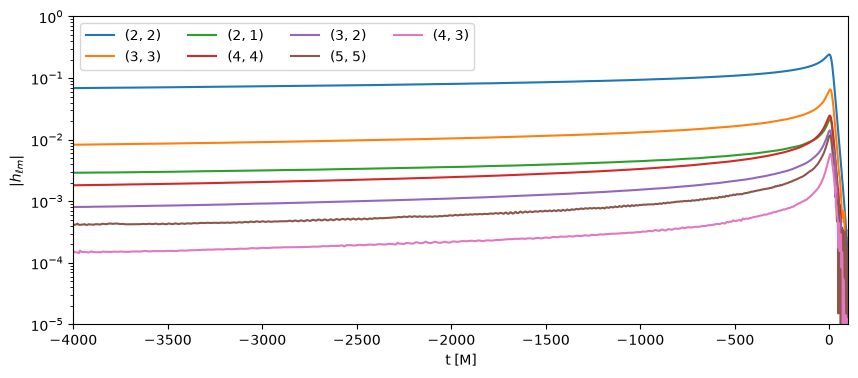

M =  20 Msun: waveform starts at f_22 =  64.4 Hz
M =  70 Msun: waveform starts at f_22 =  18.4 Hz
M = 150 Msun: waveform starts at f_22 =   8.6 Hz


In [2]:
q, chi1z, chi2z = 4.0, 0.5, -0.3
t, h_modes, _ = sur(q=q, chiA0=chi1z, chiB0=chi2z, times=np.arange(-3996, 100, 0.5))

modes = [(2, 2), (3, 3), (2, 1), (4, 4), (3, 2), (5, 5), (4, 3)]
fig, ax = plt.subplots(figsize=(10, 4))
for mode in modes:
    ax.semilogy(t, np.abs(h_modes[mode]), label=str(mode))
ax.set(xlabel="t [M]", ylabel=r"$|h_{\ell m}|$", xlim=(-4000, 100), ylim=(1e-5, 1))
ax.legend(ncol=4)
plt.show()

# Starting (2,2) frequency: f = (M omega_22) / (2 pi M), with M in seconds
M_omega_22 = np.gradient(np.unwrap(np.angle(h_modes[(2, 2)])), t)[0]
M_sun_s = 4.925490947641267e-06
for M in (20, 70, 150):
    print(f"M = {M:3d} Msun: waveform starts at f_22 = {abs(M_omega_22) / (2 * np.pi * M * M_sun_s):5.1f} Hz")

## Strain in physical units

Pass a total mass `M` (solar masses), distance `dist_mpc` (Mpc) and `units="mks"`. With an `inclination` the call returns the complex strain
$h = h_+ - i h_\times$ (LAL convention).

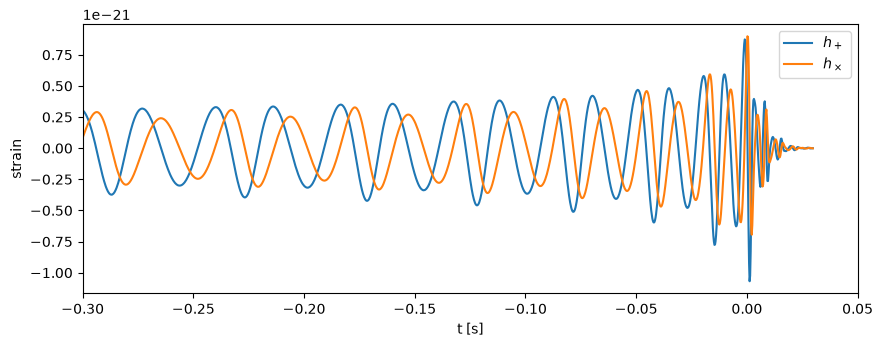

In [3]:
t_s, h, _ = sur(q=q, chiA0=chi1z, chiB0=chi2z, M=70.0, dist_mpc=400.0, units="mks",
                times=np.arange(-1.0, 0.03, 1 / 4096), inclination=np.pi / 3, phi_ref=0.0)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(t_s, h.real, label=r"$h_+$")
ax.plot(t_s, -h.imag, label=r"$h_\times$")
ax.set(xlabel="t [s]", ylabel="strain", xlim=(-0.3, 0.05))
ax.legend()
plt.show()

## Batch evaluation

Arrays of parameters are evaluated together, which is where the speed comes from. On a GPU runtime
(Runtime → Change runtime type) the cell below runs everything on the GPU.
For batches, pass the spins as `(N, 3)` vectors with zero in-plane components.

In [4]:
import time
import torch

sur_batch = DANSur(device="cuda" if torch.cuda.is_available() else "cpu")
rng = np.random.default_rng(0)
N = 1000
q_b = rng.uniform(1, 8, N)
zeros = np.zeros(N)
chi1_b = np.stack([zeros, zeros, rng.uniform(-0.8, 0.8, N)], axis=-1)
chi2_b = np.stack([zeros, zeros, rng.uniform(-0.8, 0.8, N)], axis=-1)

start = time.perf_counter()
t_b, h_b, _ = sur_batch(q=q_b, chiA0=chi1_b, chiB0=chi2_b, inclination=1.0)
elapsed = time.perf_counter() - start
print(f"[{sur_batch.device}] {N} waveforms in {elapsed:.2f} s ({1e3 * elapsed / N:.2f} ms each), output shape {h_b.shape}")

Loaded DANSur model on cpu


[cpu] 1000 waveforms in 1.37 s (1.37 ms each), output shape (1000, 8192)


## Use it in bilby

`dansur.bilby_source.dansur_binary_black_hole` is a bilby time-domain source model. It takes the usual bilby parameters
(`mass_1`, `mass_2` or `chirp_mass`, `mass_ratio` via the conversion function; aligned spins `chi_1`, `chi_2`).
Below, its frequency-domain strain is compared with IMRPhenomXHM. The overall amplitudes agree; the finer structure above
~200 Hz comes from interference between modes, which depends on each model's reference-phase convention (DANSur fixes the
mode phases at the start of its waveform, IMRPhenomXHM at `reference_frequency`), so it is not expected to line up exactly.

Loaded DANSur model on cpu


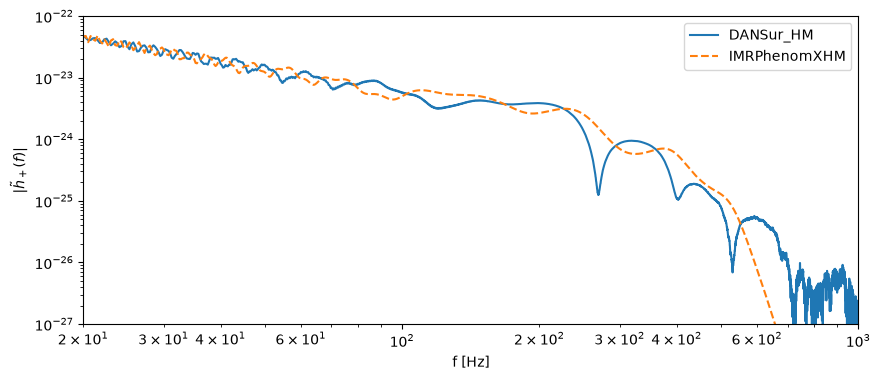

In [5]:
import bilby
from dansur.bilby_source import dansur_binary_black_hole

bilby.core.utils.logger.setLevel("WARNING")
conversion = bilby.gw.conversion.convert_to_lal_binary_black_hole_parameters
duration, fs = 4, 2048

dansur_wfg = bilby.gw.WaveformGenerator(
    duration=duration, sampling_frequency=fs, parameter_conversion=conversion,
    time_domain_source_model=dansur_binary_black_hole,
)
phenom_wfg = bilby.gw.WaveformGenerator(
    duration=duration, sampling_frequency=fs, parameter_conversion=conversion,
    frequency_domain_source_model=bilby.gw.source.lal_binary_black_hole,
    waveform_arguments=dict(waveform_approximant="IMRPhenomXHM", reference_frequency=20.0, minimum_frequency=15.0),
)

params = dict(chirp_mass=28.0, mass_ratio=0.4, chi_1=0.3, chi_2=-0.1, luminosity_distance=500.0,
              theta_jn=1.0, phase=0.3, geocent_time=0.0, ra=1.0, dec=0.2, psi=0.5)

f = dansur_wfg.frequency_array
fig, ax = plt.subplots(figsize=(10, 4))
ax.loglog(f, np.abs(dansur_wfg.frequency_domain_strain(params)["plus"]), label="DANSur_HM")
ax.loglog(f, np.abs(phenom_wfg.frequency_domain_strain(params)["plus"]), "--", label="IMRPhenomXHM")
ax.set(xlabel="f [Hz]", ylabel=r"$|\tilde h_+(f)|$", xlim=(20, 1000), ylim=(1e-27, 1e-22))
ax.legend()
plt.show()

For parameter estimation, use `dansur_wfg` like any other bilby `WaveformGenerator`, e.g. with
`bilby.gw.likelihood.GravitationalWaveTransient(interferometers, waveform_generator=dansur_wfg)`.
The DANSur waveform covers roughly the last 4000 M before merger, so choose the minimum frequency of the analysis accordingly.